# **Install Required Libraries**

In [9]:
!pip install ultralytics
!pip install roboflow


# **Load Road Traffic Sign Dataset from Roboflow**

In [10]:
from roboflow import Roboflow

rf = Roboflow(api_key="ICZtY7srig67GSfw5GWx")
project = rf.workspace("renad-omar-mewog").project("road-traffic-signs-detection-with-computer-vision-and-deep-learning")
version = project.version(6)
dataset = version.download("yolov8-obb")


loading Roboflow workspace...
loading Roboflow project...


# **Print Dataset Path**

In [11]:
print(" Dataset location:", dataset.location)

 Dataset location: /content/Road-Traffic-Signs-Detection-With-Computer-Vision-And-Deep-Learning-6


# **Train YOLOv8-OBB Model**

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8s-obb.pt")

model.train(data=f"{dataset.location}/data.yaml", epochs=70, imgsz=640)


# **Mount Google Drive**

In [12]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **Find Latest Trained best.pt Model**


In [13]:
import glob
import os
from ultralytics import YOLO

best_paths = sorted(glob.glob("/content/drive/MyDrive/Road_traffic_signs/runs/obb/train/weights/best.pt", recursive=True), key=os.path.getmtime, reverse=True)

if best_paths:
    latest_best = best_paths[0]
    print(f"Latest model found: {latest_best}")
else:
    latest_best = None
    print("No best.pt model found.")


Latest model found: /content/drive/MyDrive/Road_traffic_signs/runs/obb/train/weights/best.pt


# **Zip Trained Model Results**

In [13]:
model = YOLO("yolov8s-obb.pt")
!zip -r Road_traffic_signs.zip runs/


# **Run Trained Model on Test Image**

In [15]:
from google.colab import files
model = YOLO("yolov8s-obb.pt")
uploaded = files.upload()
test_image=list(uploaded.keys())[0]
results=model.predict(source=test_image,save=True)


Saving istockphoto-519339990-1024x1024.jpg to istockphoto-519339990-1024x1024.jpg

image 1/1 /content/istockphoto-519339990-1024x1024.jpg: 704x1024 (no detections), 72.8ms
Speed: 13.8ms preprocess, 72.8ms inference, 90.6ms postprocess per image at shape (1, 3, 704, 1024)
Results saved to runs/obb/predict


# **Load and Run Prediction Using Best Model**

In [17]:
model = YOLO("/content/drive/MyDrive/Road_traffic_signs/runs/obb/train/weights/best.pt")
results = model.predict(source=test_image, save=True)



image 1/1 /content/istockphoto-519339990-1024x1024.jpg: 448x640 None48.0ms
Speed: 3.2ms preprocess, 48.0ms inference, 346.1ms postprocess per image at shape (1, 3, 448, 640)
Results saved to runs/obb/predict2


# **Display Prediction Result in Colab**

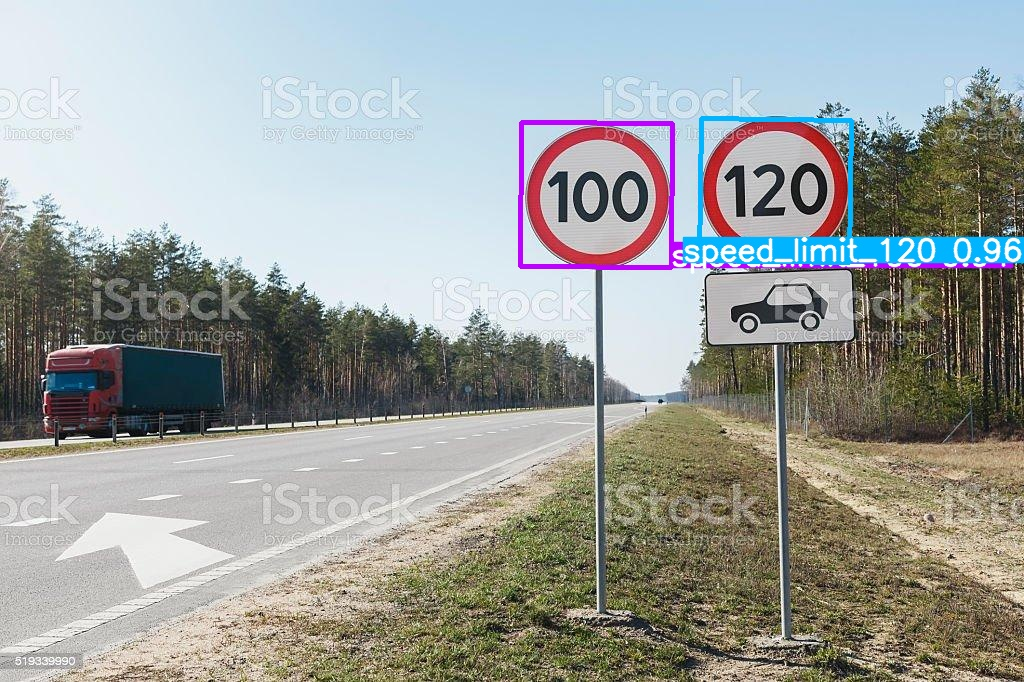

In [19]:
import os
from IPython.display import Image, display

result_img_path = "/content/runs/obb/predict2/istockphoto-519339990-1024x1024.jpg"

if os.path.exists(result_img_path):
    display(Image(filename=result_img_path))
else:
    print("Result image not found. Check the file name inside runs/predict/predict/")


# Display Training Result **Images**

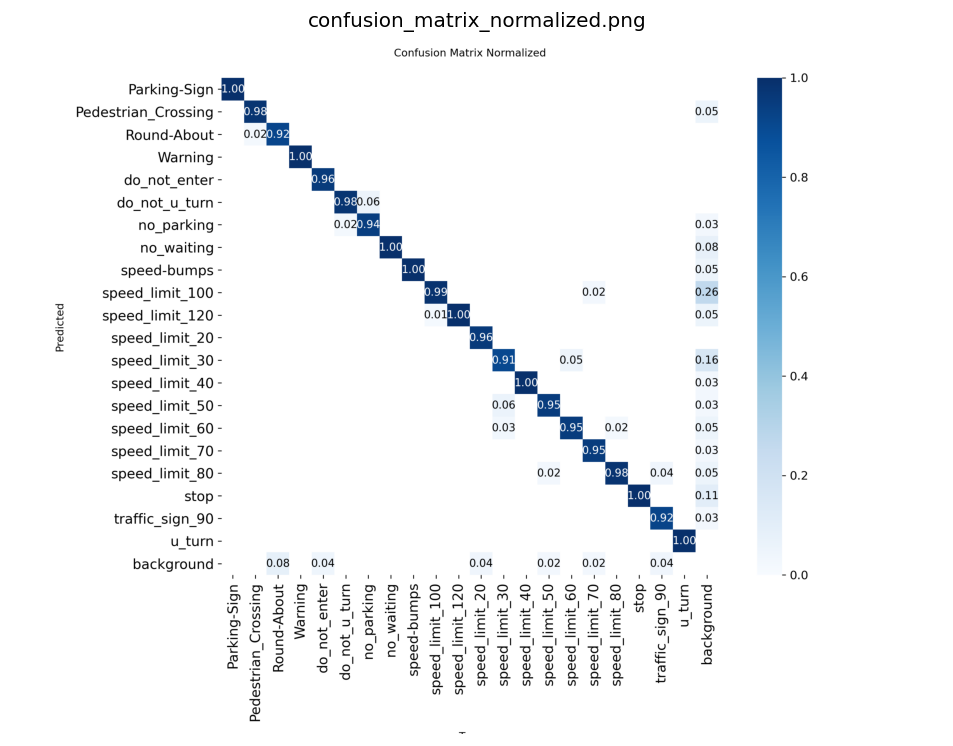

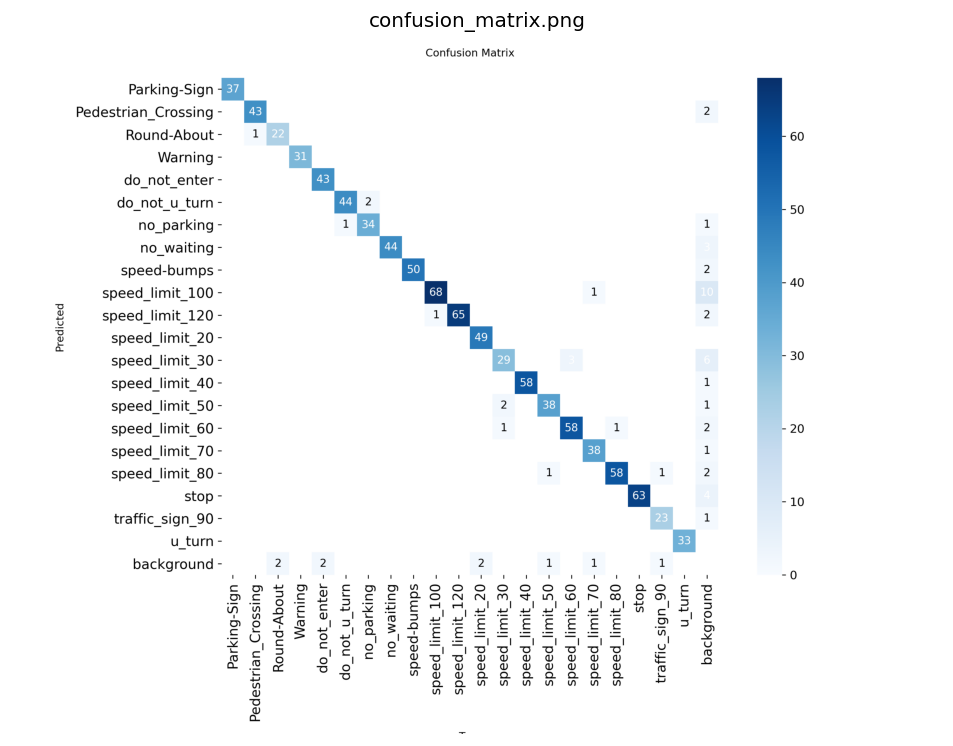

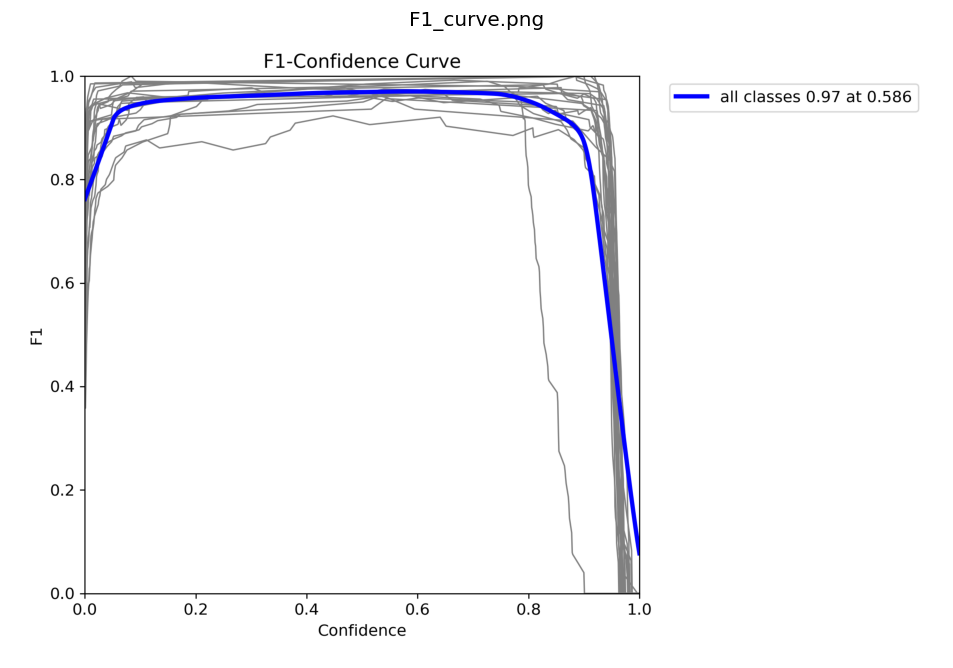

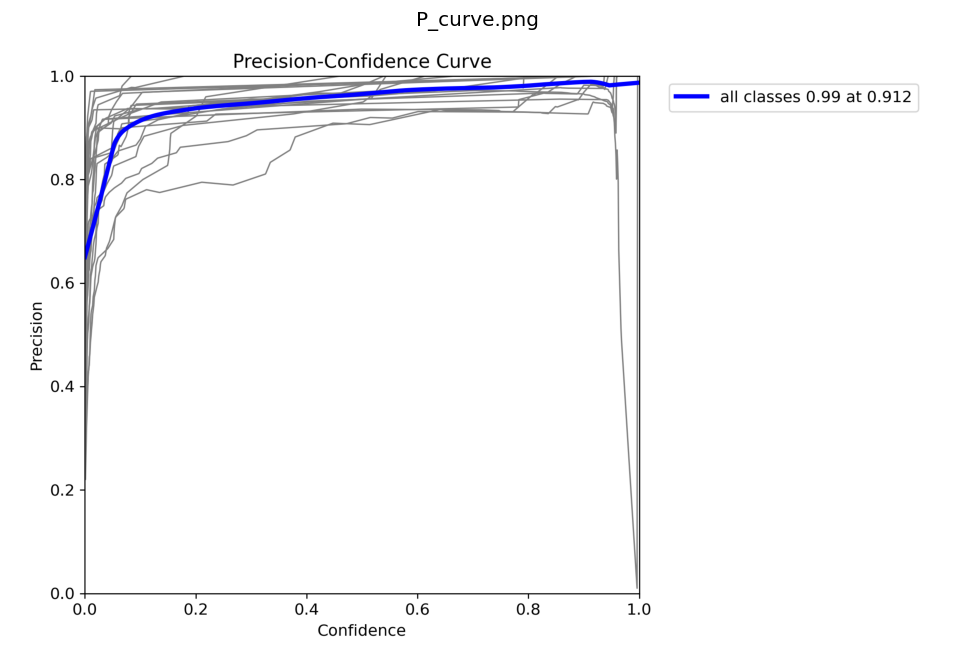

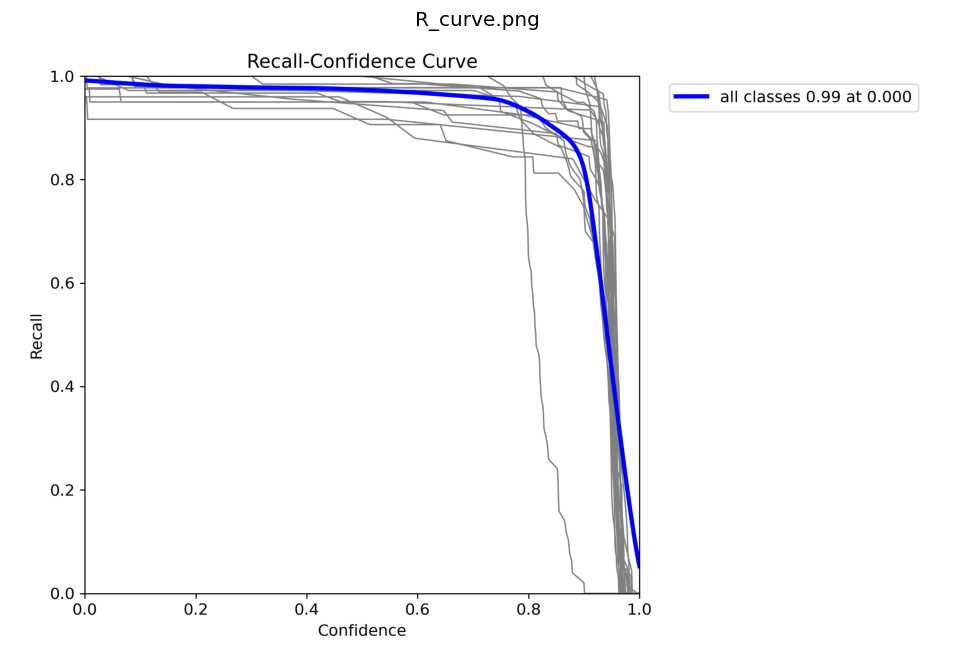

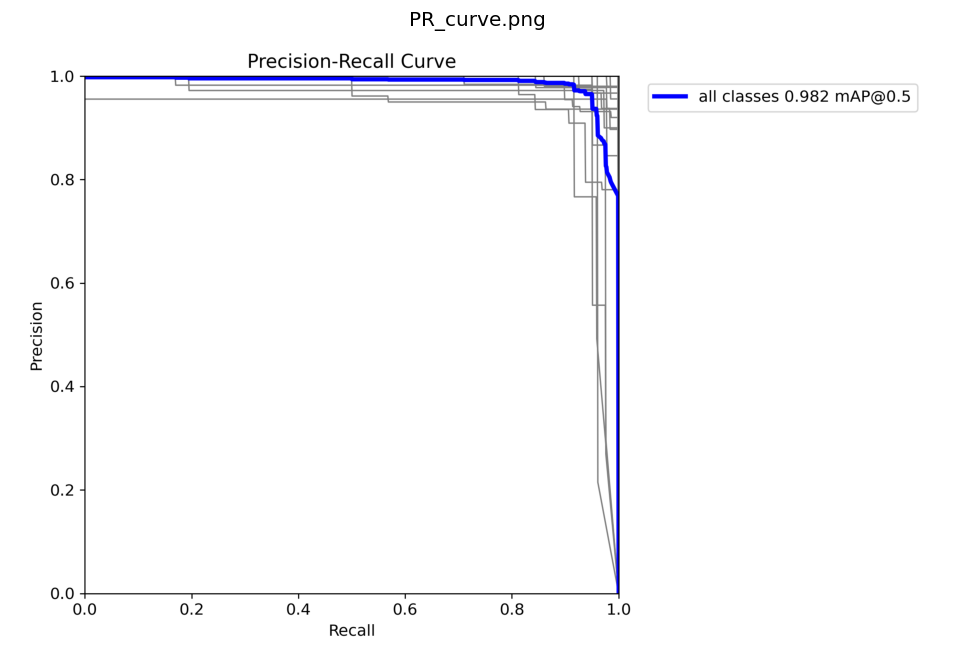

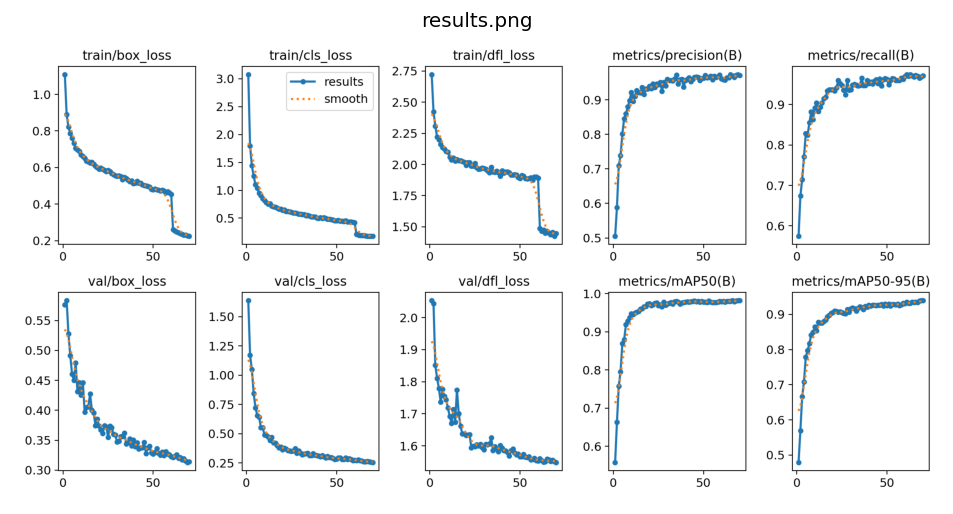

In [27]:
import os
import cv2
import matplotlib.pyplot as plt

def display_training_results(results_path, image_files):
    for image_file in image_files:
        image_path = os.path.join(results_path, image_file)
        if not os.path.exists(image_path):
            print(f"Image not found: {image_path}")
            continue

        img = cv2.imread(image_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(10, 10), dpi=120)
        plt.imshow(img)
        plt.axis('off')
        plt.title(image_file)
        plt.show()

image_files = [
    'confusion_matrix_normalized.png',
    "confusion_matrix.png",
    'F1_curve.png',
    'P_curve.png',
    'R_curve.png',
    'PR_curve.png',
    'results.png'

]

results_path = '/content/drive/MyDrive/Road_traffic_signs/runs/obb/train'

display_training_results(results_path, image_files)


# **Load and Display Last 10 Epochs from Training Results**

In [21]:
import pandas as pd

results_path = '/content/drive/MyDrive/Road_traffic_signs/runs/obb/train/results.csv'
Result_Final_model = pd.read_csv(results_path)

print("Last 10 training epochs:")
display(Result_Final_model.tail(10))


Last 10 training epochs:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
60,61,5221.66,0.26151,0.21119,1.48639,0.95801,0.97398,0.98016,0.93522,0.32146,0.27143,1.55996,0.000061,0.000061,0.000061
61,62,5304.96,0.25333,0.19870,1.46626,0.95728,0.97025,0.97780,0.93224,0.32316,0.27505,1.55436,0.000055,0.000055,0.000055
62,63,5387.65,0.24776,0.19197,1.47429,0.96447,0.97460,0.98002,0.93146,0.32578,0.26917,1.54985,0.000049,0.000049,0.000049
63,64,5471.02,0.24360,0.19200,1.44840,0.96435,0.97160,0.98000,0.93511,0.31957,0.26575,1.55096,0.000044,0.000044,0.000044
64,65,5553.43,0.23965,0.18861,1.46360,0.97343,0.96795,0.98014,0.93357,0.32147,0.26066,1.55842,0.000038,0.000038,0.000038
65,66,5636.73,0.23569,0.18624,1.44992,0.97009,0.97240,0.98189,0.93562,0.31750,0.26126,1.55620,0.000032,0.000032,0.000032
66,67,5719.63,0.23067,0.17928,1.43792,0.96454,0.97069,0.97916,0.93366,0.31936,0.26327,1.55158,0.000027,0.000027,0.000027
67,68,5803.08,0.22997,0.17894,1.45497,0.97037,0.96594,0.98110,0.93844,0.31505,0.26055,1.55495,0.000021,0.000021,0.000021
68,69,5886.35,0.22663,0.17895,1.42390,0.97335,0.96887,0.98197,0.93943,0.31297,0.25700,1.55026,0.000015,0.000015,0.000015
69,70,5968.69,0.22415,0.17481,1.44752,0.97037,0.97118,0.98197,0.93940,0.31421,0.25454,1.54847,0.000010,0.000010,0.000010


# **Plot Training and Validation Metrics**

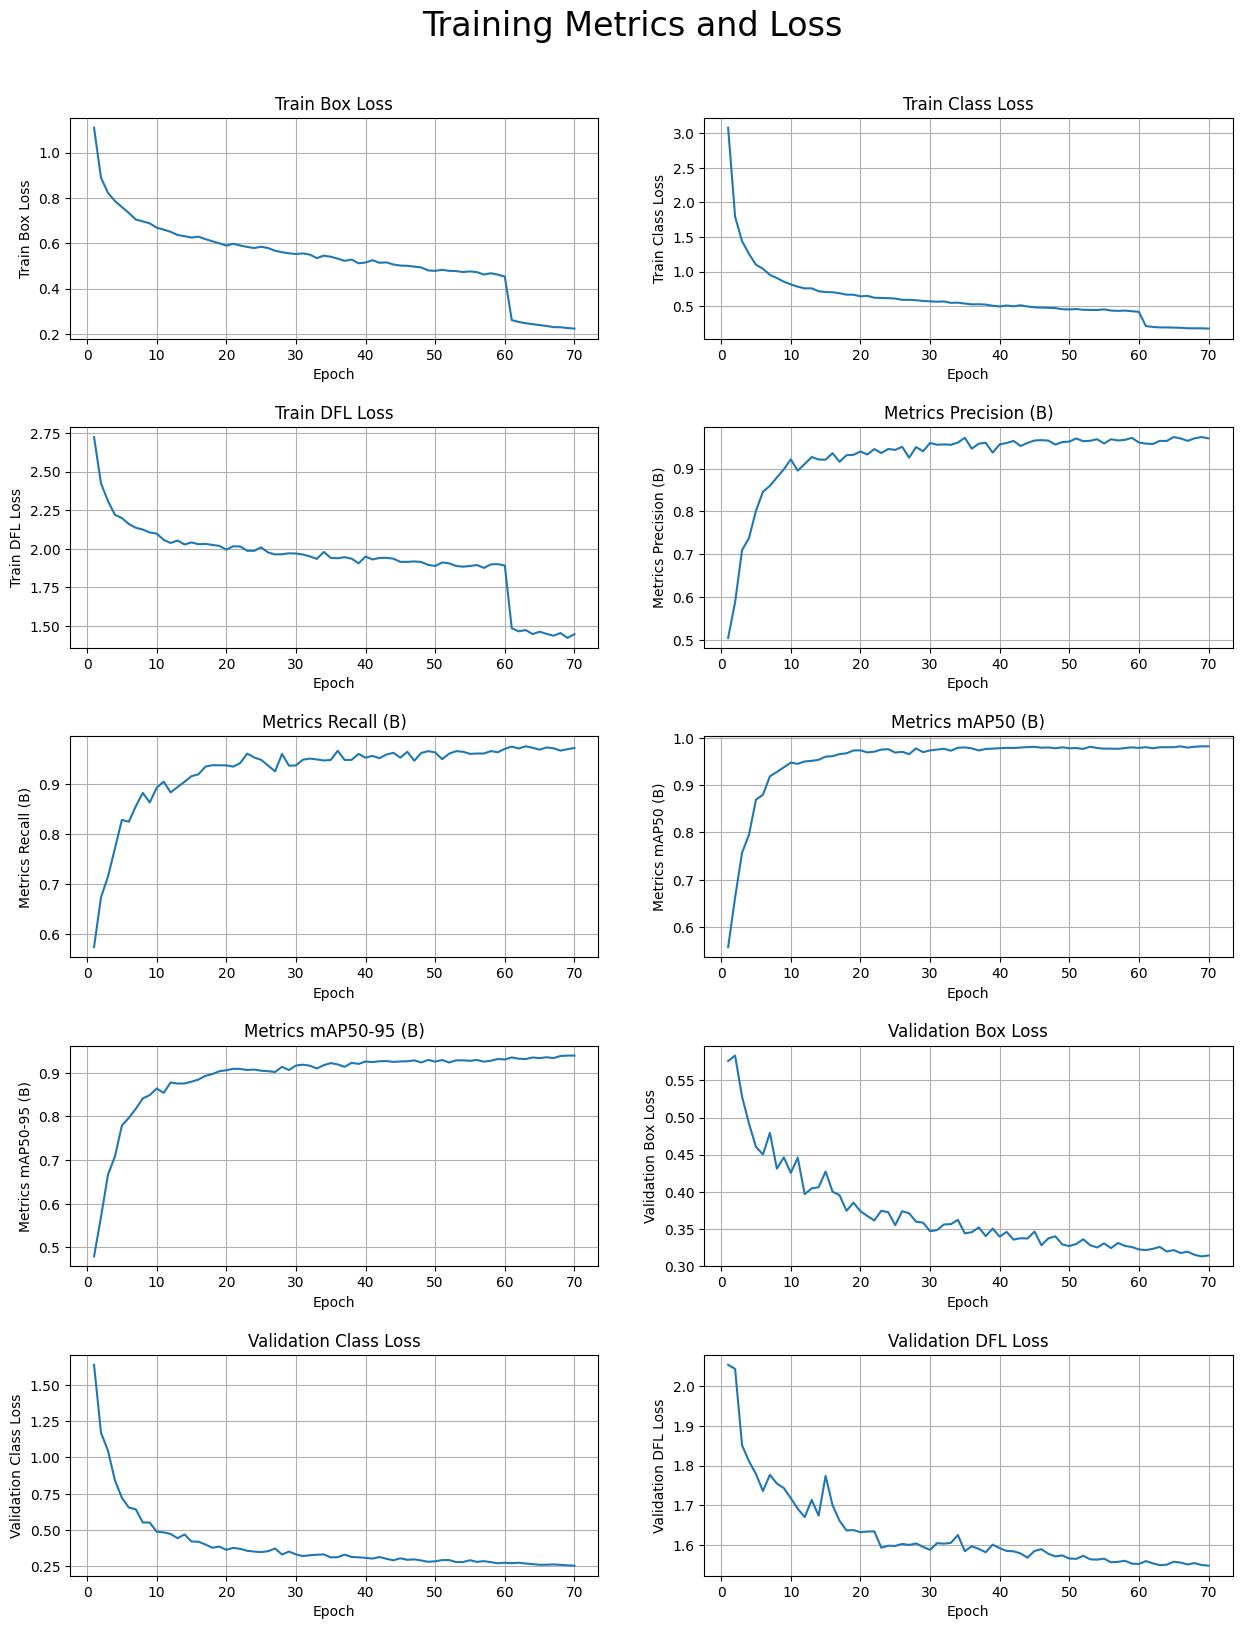

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

results_path = '/content/drive/MyDrive/Road_traffic_signs/runs/obb/train/results.csv'
Result_Final_model = pd.read_csv(results_path)

Result_Final_model.columns = Result_Final_model.columns.str.strip()

plots_info = [
    ('train/box_loss', 'Train Box Loss'),
    ('train/cls_loss', 'Train Class Loss'),
    ('train/dfl_loss', 'Train DFL Loss'),
    ('metrics/precision(B)', 'Metrics Precision (B)'),
    ('metrics/recall(B)', 'Metrics Recall (B)'),
    ('metrics/mAP50(B)', 'Metrics mAP50 (B)'),
    ('metrics/mAP50-95(B)', 'Metrics mAP50-95 (B)'),
    ('val/box_loss', 'Validation Box Loss'),
    ('val/cls_loss', 'Validation Class Loss'),
    ('val/dfl_loss', 'Validation DFL Loss')
]

fig, axs = plt.subplots(nrows=5, ncols=2, figsize=(15, 18))
axs = axs.flatten()

for i, (col, title) in enumerate(plots_info):
    if col in Result_Final_model.columns:
        sns.lineplot(x='epoch', y=col, data=Result_Final_model, ax=axs[i])
        axs[i].set_title(title)
        axs[i].set_xlabel('Epoch')
        axs[i].set_ylabel(title)
        axs[i].grid(True)
    else:
        axs[i].text(0.5, 0.5, f'Column "{col}" not found', ha='center', va='center')
        axs[i].set_title(title)
        axs[i].set_xlabel('')
        axs[i].set_ylabel('')

plt.suptitle('Training Metrics and Loss', fontsize=24)
plt.subplots_adjust(top=0.92, hspace=0.4)
plt.show()


# **Evaluate Best YOLOv8-OBB Model on Validation Set**

In [23]:
valid_model = YOLO("/content/drive/MyDrive/Road_traffic_signs/runs/obb/train/weights/best.pt")

metrics = valid_model.val(split='val')

print("Precision (B):", metrics.results_dict["metrics/precision(B)"])
print("Recall (B):", metrics.results_dict["metrics/recall(B)"])
print("mAP@0.5 (B):", metrics.results_dict["metrics/mAP50(B)"])
print("mAP@0.5:0.95 (B):", metrics.results_dict["metrics/mAP50-95(B)"])


Ultralytics 8.3.146 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLOv8s-obb summary (fused): 81 layers, 11,419,698 parameters, 0 gradients, 29.5 GFLOPs


100%|██████████| 755k/755k [00:00<00:00, 111MB/s]

val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1204.7±495.8 MB/s, size: 41.3 KB)



val: Scanning /content/Road-Traffic-Signs-Detection-With-Computer-Vision-And-Deep-Learning-6/valid/labels... 800 images, 0 backgrounds, 0 corrupt: 100%|██████████| 800/800 [00:00<00:00, 2179.30it/s]

val: New cache created: /content/Road-Traffic-Signs-Detection-With-Computer-Vision-And-Deep-Learning-6/valid/labels.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 50/50 [00:15<00:00,  3.24it/s]


                   all        800        952      0.973      0.969      0.982       0.94
          Parking-Sign         37         37      0.991          1      0.995      0.991
   Pedestrian_Crossing         44         44      0.949      0.977      0.949      0.906
           Round-About         24         24          1      0.912      0.958      0.915
               Warning         31         31      0.987          1      0.995      0.954
          do_not_enter         45         45          1      0.938      0.995      0.969
         do_not_u_turn         45         45      0.961      0.978      0.991      0.964
            no_parking         33         36      0.967      0.972      0.971      0.945
            no_waiting         44         44      0.936      0.991      0.969      0.959
           speed-bumps         50         50      0.968          1      0.992      0.754
       speed_limit_100         62         69      0.928      0.986      0.986      0.927
       speed_limit_12

# **Download YOLOv8-OBB Dataset**

In [24]:
dataset = version.download("yolov8-obb")


# **Visualize Sample Validation Images with Predictions**


0: 640x640 None19.9ms
Speed: 2.6ms preprocess, 19.9ms inference, 4.7ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 None16.9ms
Speed: 2.3ms preprocess, 16.9ms inference, 4.4ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 None17.0ms
Speed: 2.5ms preprocess, 17.0ms inference, 4.0ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 None17.0ms
Speed: 4.2ms preprocess, 17.0ms inference, 5.1ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 None17.1ms
Speed: 2.5ms preprocess, 17.1ms inference, 5.9ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 None17.0ms
Speed: 2.5ms preprocess, 17.0ms inference, 4.3ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 None17.0ms
Speed: 3.1ms preprocess, 17.0ms inference, 5.2ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 None16.3ms
Speed: 2.3ms preprocess, 16.3ms inference, 4.1ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 None16.2ms
Speed: 2.3ms prep

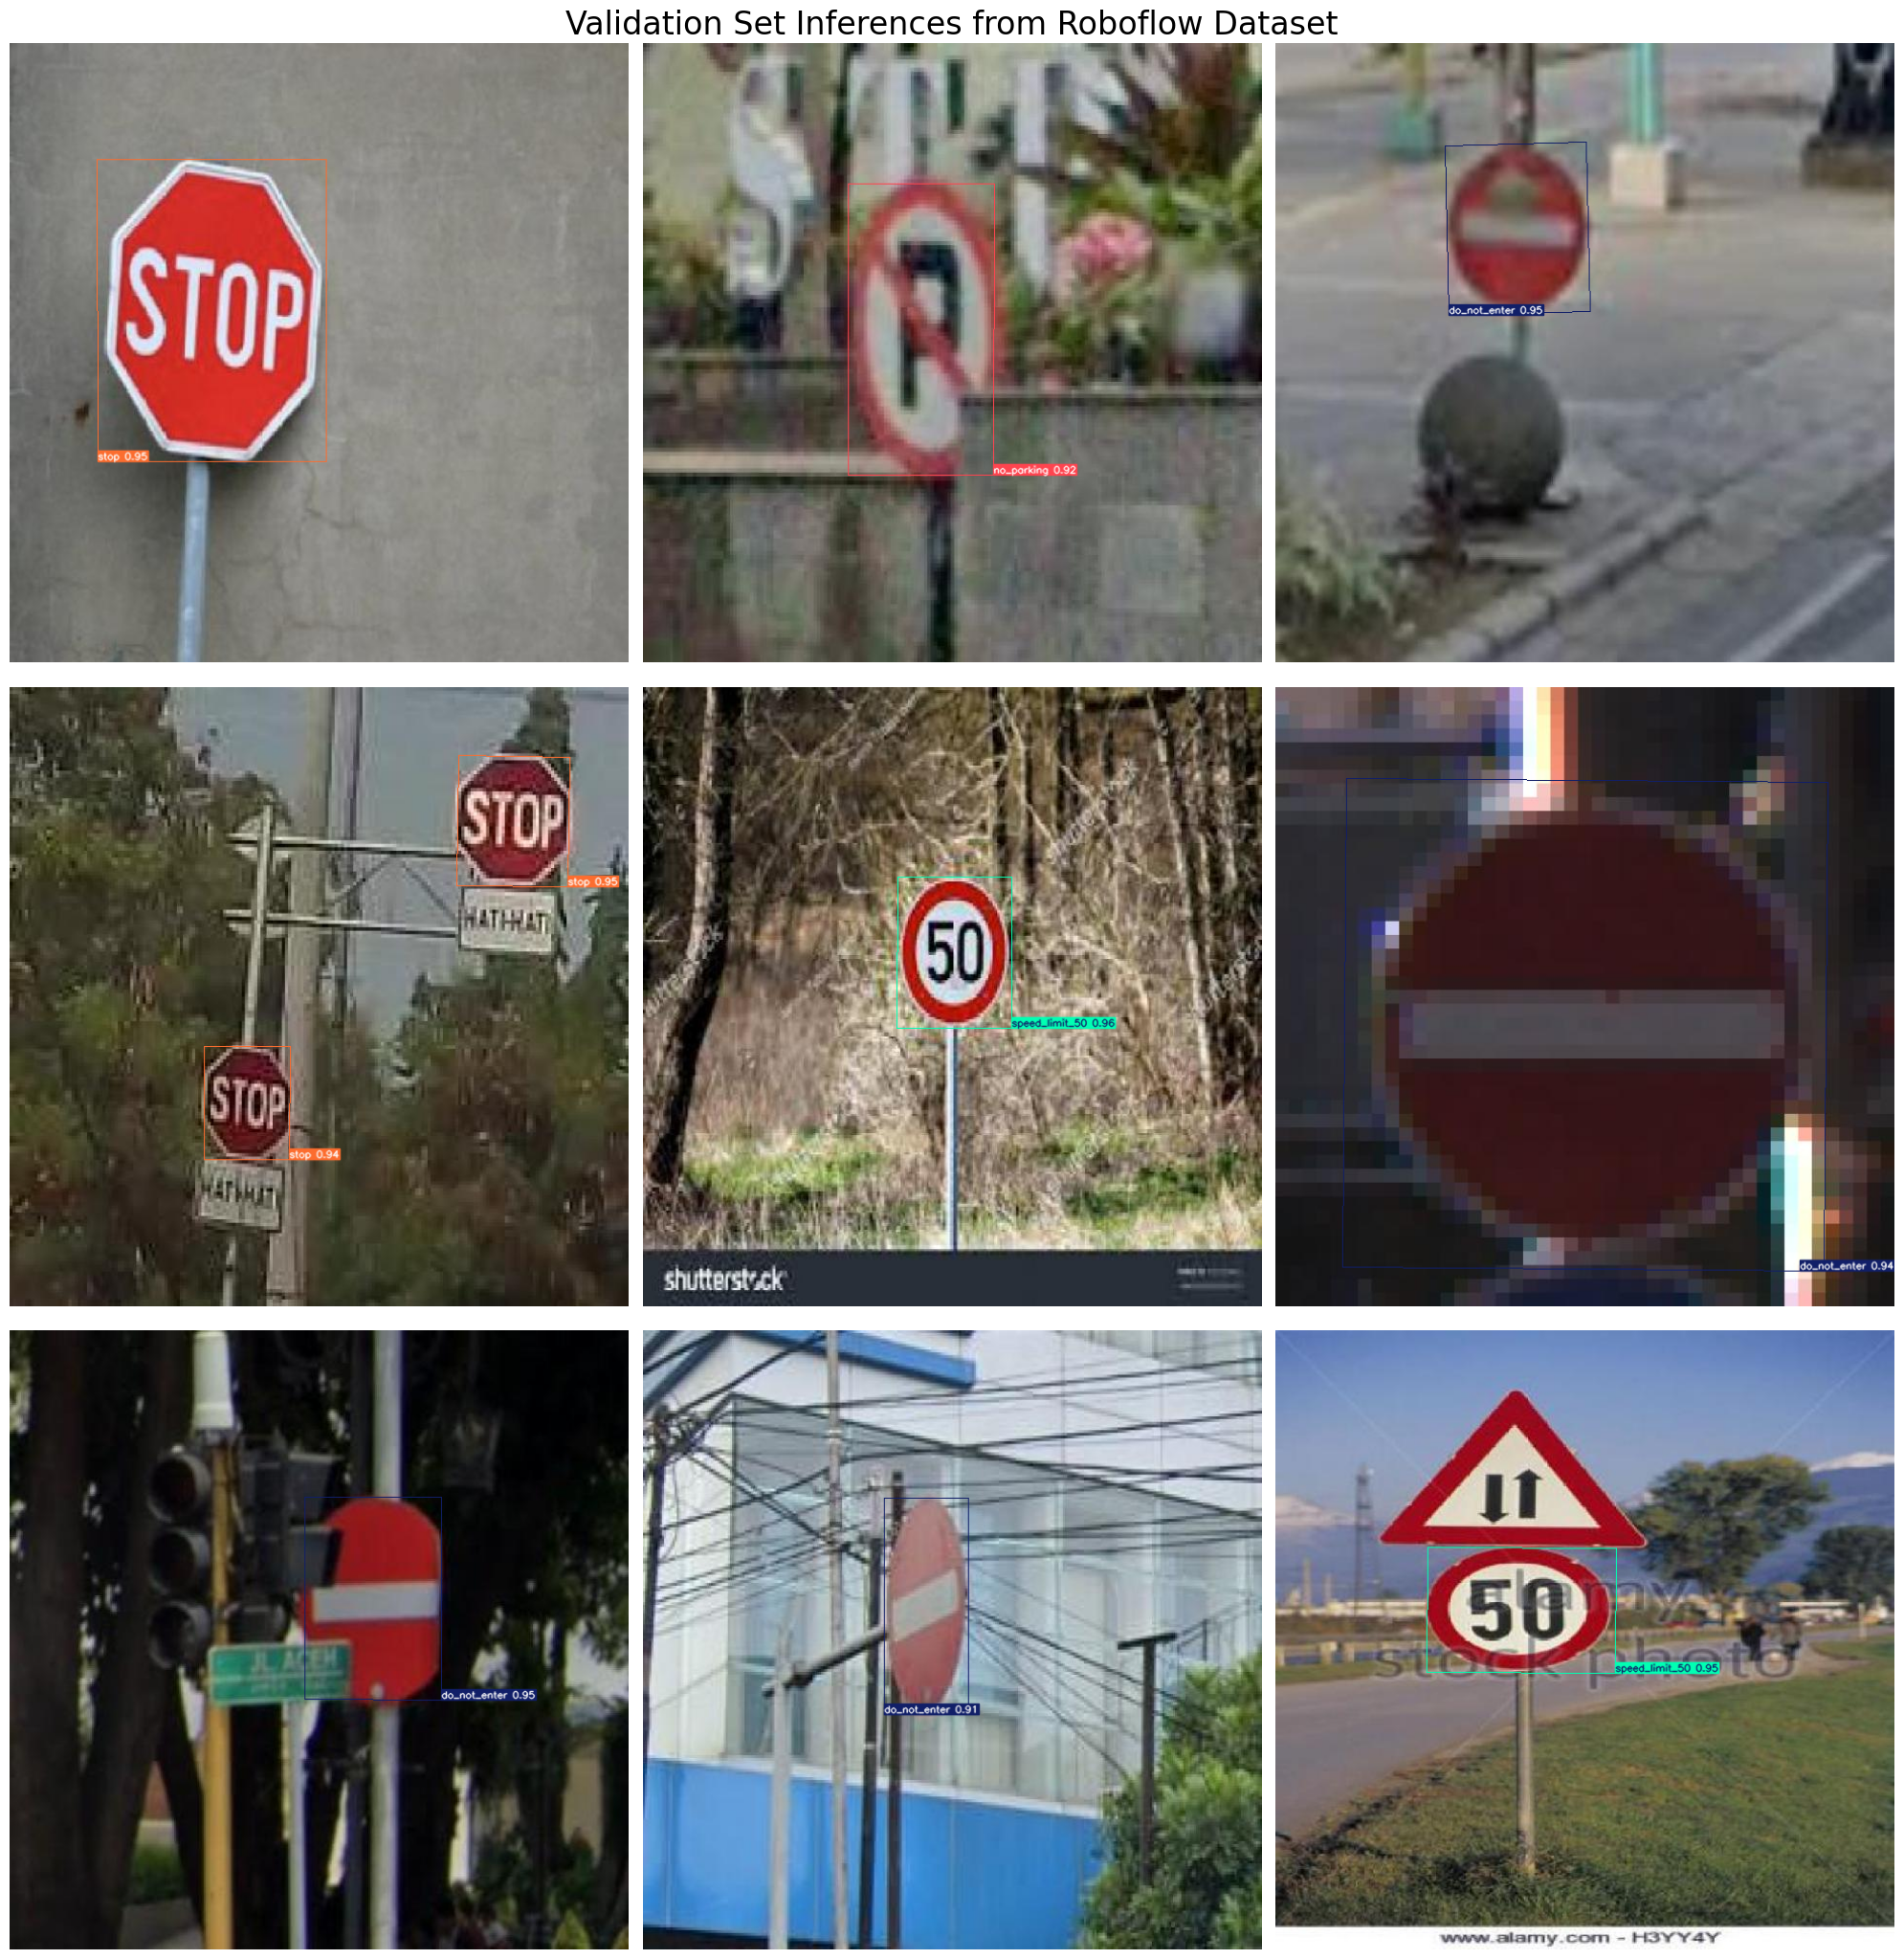

In [25]:
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt

def normalize_image(image):
    return image / 255.0

def resize_image(image, size=(640, 640)):
    return cv2.resize(image, size)

valid_images_path = os.path.join(dataset.location, 'valid', 'images')

image_files = [file for file in os.listdir(valid_images_path) if file.endswith('.jpg')]

if len(image_files) > 0:
    num_images = len(image_files)
    step_size = max(1, num_images // 9)
    selected_images = [image_files[i] for i in range(0, num_images, step_size)]

    fig, axes = plt.subplots(3, 3, figsize=(20, 21))
    fig.suptitle('Validation Set Inferences from Roboflow Dataset', fontsize=24)

    for i, ax in enumerate(axes.flatten()):
        if i < len(selected_images):
            image_path = os.path.join(valid_images_path, selected_images[i])
            image = cv2.imread(image_path)
            if image is not None:
                resized_image = resize_image(image, size=(640, 640))
                normalized_image = normalize_image(resized_image)
                normalized_image_uint8 = (normalized_image * 255).astype(np.uint8)

                results = valid_model.predict(source=normalized_image_uint8, imgsz=640, conf=0.5)

                annotated_image = results[0].plot(line_width=1)
                annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
                ax.imshow(annotated_image_rgb)
            else:
                print(f"Failed to load image: {image_path}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("No images found in valid/images folder.")


In [60]:
from google.colab import files

uploaded = files.upload()
video_name = list(uploaded.keys())[0]


In [60]:
from ultralytics import YOLO

valid_model = YOLO("/content/drive/MyDrive/Road_traffic_signs/runs/obb/train/weights/best.pt")
valid_model.predict(source=video_name, save=True, conf=0.5)
